In [604]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

In [1358]:
def TS_ber_band(y, theta, T, M, random=False):
    
    results = defaultdict(list)
    K = len(theta)
    
    if random:
        alpha = np.random.rand(K)#np.random.randint(1, 10, size=K)
        beta = np.random.rand(K)#np.random.randint(1, 10, size=K)
    else:
        alpha = np.ones(K) 
        beta = np.ones(K)
    
    rw = 0
    tau = np.nan
    theta_max = np.max(theta)
    
    for t in range(T):

        theta_hat = np.random.beta(alpha, beta)
        A_t = np.argmax(theta_hat)
        regret_t = theta_max - theta[A_t]
        if len(y) == 0:
            r_t = np.random.binomial(1, theta[A_t])
        else:
            r_t = y[t, A_t]
        
        alpha[A_t] += r_t
        beta[A_t] += 1 - r_t
        
        rw += r_t
        
        results['t'].append(t)
        results['A'].append(A_t)
        results['rw'].append(rw)
        results['r_t'].append(r_t)
        results['regret_t'].append(regret_t)
        #results['alpha'].append(alpha)
        
        if rw >= M and np.isnan(tau):
            tau = t
            return tau, results

        
def G_ber_band(y, theta, T, M, random=False):
    
    results = defaultdict(list)
    K = len(theta)
    
    if random:
        alpha = np.random.rand(K)#np.random.randint(1, 10, size=K)
        beta = np.random.rand(K)#np.random.randint(1, 10, size=K)
    else:
        alpha = np.ones(K) 
        beta = np.ones(K)
    
    rw = 0
    tau = np.nan
    theta_max = np.max(theta)
    
    for t in range(T):

        theta_hat = alpha / (alpha + beta)#np.random.beta(alpha, beta)
        A_t = np.argmax(theta_hat)
        regret_t = theta_max - theta[A_t]
        if len(y) == 0:
            r_t = np.random.binomial(1, theta[A_t])
        else:
            r_t = y[t, A_t]
        
        alpha[A_t] += r_t
        beta[A_t] += 1 - r_t
        
        rw += r_t
        
        results['t'].append(t)
        results['A'].append(A_t)
        results['rw'].append(rw)
        results['r_t'].append(r_t)
        results['regret_t'].append(regret_t)
        
        if rw >= M and np.isnan(tau):
            tau = t
            return tau, results
            

In [1323]:
def TS_Dir_ber_band(y, theta, T, M, random=False):
    
    results = defaultdict(list)
    K = len(theta)
    
    if random:
        alpha = np.random.rand(K)#np.random.randint(1, 10, size=K)
        #beta = np.random.rand(K)#np.random.randint(1, 10, size=K)
    else:
        alpha = np.ones(K) 
        #beta = np.ones(K)
    
    rw = 0
    tau = np.nan
    theta_max = np.max(theta)
    
    for t in range(T):

        #theta_hat = np.random.beta(alpha, beta)
        theta_hat = np.random.dirichlet(alpha, 1).flatten()
        A_t = np.argmax(theta_hat)
        regret_t = theta_max - theta[A_t]
        if len(y) == 0:
            r_t = np.random.binomial(1, theta[A_t])
        else:
            r_t = y[t, A_t]
        
        alpha[A_t] += r_t
        #beta[A_t] += 1 - r_t
        
        rw += r_t
        
        results['t'].append(t)
        results['A'].append(A_t)
        results['rw'].append(rw)
        results['r_t'].append(r_t)
        results['regret_t'].append(regret_t)
        
        if rw >= M and np.isnan(tau):
            tau = t
            return tau, results

In [1324]:
def Dirich_ber_band(y, theta, T, M, alpha0, random=False):
    
    results = defaultdict(list)
    K = len(theta)
    if random:
        n = np.random.randint(1, K, K)
    else:
        n = np.ones(K)
    alpha = alpha0 * n
    #alpha = alpha0 * np.power(n, 1.5)
    #alpha = alpha0 * np.exp(n-1)
    
    rw = 0
    tau = np.nan
    theta_max = np.max(theta)
    
    for t in range(T):
        
        mu = np.random.dirichlet(alpha, 1).flatten()#.transpose()
        A_t = np.random.choice(range(K), p=mu)
        
        #theta_hat = np.random.beta(alpha, beta)
        #A_t = np.argmax(theta_hat)
        
        regret_t = theta_max - theta[A_t]
        if len(y) == 0:
            r_t = np.random.binomial(1, theta[A_t])
        else:
            r_t = y[t, A_t]
        
        #print(np.max([n[A_t] + (2 * r_t - 1), 1]))
        #n[A_t] = np.max([n[A_t] + (2 * r_t - 1), 1])
        n[A_t] = n[A_t] + r_t
        alpha = alpha0 * n
        #alpha = alpha0 * np.power(n, 1.5)
        #alpha = alpha0 * np.exp(n-1)
        
        rw += r_t
        
        results['t'].append(t)
        results['A'].append(A_t)
        results['rw'].append(rw)
        results['r_t'].append(r_t)
        results['regret_t'].append(regret_t)
        
        results['mu'].append(mu)
        results['alpha'].append(alpha)
        results['n'].append(n.copy())
        
        if rw >= M and np.isnan(tau):
            tau = t
            return tau, results
        
    return np.inf, results
        

In [1395]:
#theta = [.9,.5,.3]
theta = [.9,.8,.7]
S = 1000
oracle_res = defaultdict(list)
rand_res = defaultdict(list)
TS_res = defaultdict(list)
G_res = defaultdict(list)
D_res = defaultdict(list)

for M in np.concatenate([np.arange(1,100,20), np.arange(100,500,100)]):
    
    print(M)
    N = 2000
    #M = 5
    #rho = .5  
    taus_rand = list()
    taus_perf = list()
    taus_TS = list()
    taus_G = list()
    taus_D = list()
    for i in range(S):
        
        theta = (.2*np.random.rand(3) + .7)
        y = np.random.binomial(np.ones((N,1), dtype=int), theta)
        
        # Random
        x_rand = np.random.randint(3, size=N)
        r_rand = y[np.arange(N), x_rand]
        s_rand = r_rand.cumsum()
        
        # Oracle
        #y_ = y[:,0].copy()
        s_perf = y[:,np.argmax(theta)].cumsum()
        
        # TS
        tau_TS, _ = TS_ber_band(y=y, theta=theta, T=N, M=M, random=True)
        
        # G
        tau_G, _ = G_ber_band(y=y, theta=theta, T=N, M=M, random=True)
        
        # Dirich
        #tau_D, _ = TS_Dir_ber_band(y=y, theta=theta, T=N, M=M, random=True)
        #print(Dirich_ber_band(y=y, theta=theta, T=T, M=M, alpha0=1))

        if s_rand.max() >= M:
            taus_rand.append(np.where(s_rand == int(M))[0][0]+1)
        else:
            taus_rand.append(np.inf)
        if s_perf.max() >= M:
            taus_perf.append(np.where(s_perf == int(M))[0][0]+1)
        else:
            taus_perf.append(np.inf)
        
        taus_TS.append(tau_TS + 1)
        
        taus_G.append(tau_G + 1)
        
        #taus_D.append(tau_D + 1)
    
    oracle_res['M'].append(M)
    oracle_res['mean_tau'].append(np.array(taus_perf).mean())
    oracle_res['std_tau'].append(np.array(taus_perf).std())
    
    rand_res['M'].append(M)
    rand_res['mean_tau'].append(np.array(taus_rand).mean())
    rand_res['std_tau'].append(np.array(taus_rand).std())
    
    TS_res['M'].append(M)
    TS_res['mean_tau'].append(np.array(taus_TS).mean())
    TS_res['std_tau'].append(np.array(taus_TS).std())
    
    G_res['M'].append(M)
    G_res['mean_tau'].append(np.array(taus_G).mean())
    G_res['std_tau'].append(np.array(taus_G).std())
    
    #D_res['M'].append(M)
    #D_res['mean_tau'].append(np.array(taus_D).mean())
    #D_res['std_tau'].append(np.array(taus_D).std())
    
    
    print((np.array(taus_perf).mean(), 
           np.array(taus_rand).mean(), 
           np.array(taus_TS).mean(), 
           np.array(taus_G).mean()))
           #np.array(taus_D).mean()))
    
    print((np.array(taus_perf).std(), 
           np.array(taus_rand).std(), 
           np.array(taus_TS).std(),
           np.array(taus_G).std()))
           #np.array(taus_D).std()))

1
(1.191, 1.269, 1.281, 1.24)
(0.4842716179996511, 0.5555528777713243, 0.586548378226383, 0.5462600113499065)
21
(24.714, 26.32, 26.106, 26.203)
(2.3795386107394854, 2.824464551025557, 2.8239624643397794, 3.2021541187144633)
41
(48.418, 51.386, 50.65, 51.271)
(3.8749549674802672, 4.242287590439856, 4.263977016823613, 5.145829282049688)
61
(72.014, 76.667, 75.035, 75.956)
(5.022330534721903, 5.400565803691313, 5.361322131713408, 7.04131124152313)
81
(95.383, 101.132, 99.106, 100.503)
(6.192762792163124, 6.601710081486463, 6.645958471131159, 8.630294954403356)
100
(118.351, 125.304, 122.462, 124.563)
(7.468587483587509, 7.310648671629625, 7.6770147844067615, 10.478932722372065)
200
(235.749, 250.957, 242.958, 248.96)
(12.883477752532505, 12.75622009060678, 13.715182681976934, 19.87743444210042)
300
(353.356, 375.736, 363.091, 373.052)
(18.926469929704272, 19.07396927752585, 20.928132238687713, 28.336112930322678)
400
(471.662, 501.341, 482.991, 499.367)
(24.08824933447842, 22.56512173687

In [1396]:
oracle_res_df = pd.DataFrame(oracle_res)
rand_res_df = pd.DataFrame(rand_res)
TS_res_df = pd.DataFrame(TS_res)
G_res_df = pd.DataFrame(G_res)
#D_res_df = pd.DataFrame(D_res)

oracle_res_df['M/tau'] = oracle_res_df['M'] / oracle_res_df['mean_tau']
rand_res_df['M/tau'] = rand_res_df['M'] / rand_res_df['mean_tau']
TS_res_df['M/tau'] = TS_res_df['M'] / TS_res_df['mean_tau']
G_res_df['M/tau'] = G_res_df['M'] / G_res_df['mean_tau']
#D_res_df['M/tau'] = D_res_df['M'] / D_res_df['mean_tau']

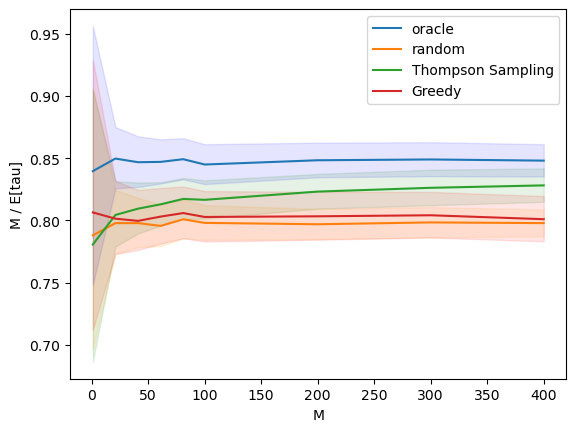

In [1397]:
wide = .3
plt.plot(oracle_res_df['M'],
         oracle_res_df['M']/(oracle_res_df['mean_tau']), label='oracle')

plt.fill_between(oracle_res_df['M'],
                 oracle_res_df['M']/(oracle_res_df['mean_tau'] + wide*oracle_res_df['std_tau']),
                 oracle_res_df['M']/(oracle_res_df['mean_tau'] - wide*oracle_res_df['std_tau']),color='b', alpha=.1)

plt.plot(rand_res_df['M'],
         rand_res_df['M']/(rand_res_df['mean_tau']), label='random')

plt.fill_between(rand_res_df['M'],
                 rand_res_df['M']/(rand_res_df['mean_tau'] + wide*rand_res_df['std_tau']),
                 rand_res_df['M']/(rand_res_df['mean_tau'] - wide*rand_res_df['std_tau']), color='orange', alpha=.1)


plt.plot(TS_res_df['M'],
         TS_res_df['M']/(TS_res_df['mean_tau']), label='Thompson Sampling')

plt.fill_between(TS_res_df['M'],
                 TS_res_df['M']/(TS_res_df['mean_tau'] + wide*TS_res_df['std_tau']),
                 TS_res_df['M']/(TS_res_df['mean_tau'] - wide*TS_res_df['std_tau']), color='g', alpha=.1)

plt.plot(G_res_df['M'],
         G_res_df['M']/(G_res_df['mean_tau']), label='Greedy')

plt.fill_between(G_res_df['M'],
                 G_res_df['M']/(G_res_df['mean_tau'] + wide*G_res_df['std_tau']),
                 G_res_df['M']/(G_res_df['mean_tau'] - wide*G_res_df['std_tau']), color='r', alpha=.1)

#plt.plot(D_res_df['M'],
#         D_res_df['M']/(D_res_df['mean_tau']), label='Dirichlet')

#plt.fill_between(D_res_df['M'],
#                 D_res_df['M']/(D_res_df['mean_tau'] + wide*D_res_df['std_tau']),
#                 D_res_df['M']/(D_res_df['mean_tau'] - wide*D_res_df['std_tau']), color='purple', alpha=.1)


plt.xlabel('M')
plt.ylabel('M / E[tau]')
#plt.ylim((0.7,1))

plt.legend()

In [1394]:
((.2*np.random.rand(1000000) + .7)).mean()

0.7999963989335298

In [1368]:
np.diag(np.dot(np.dot(x.T, A), x)) / 100

array([0.0773846 , 0.0890753 , 0.07269124, 0.06847053, 0.09098901])

In [588]:
x.var(0)

array([0.0773846 , 0.0890753 , 0.07269124, 0.06847053, 0.09098901])

In [576]:
for M in np.concatenate([np.arange(1,100,20), np.arange(100,500,100)]):
    print((M/N/.9, M/N/.8))

(0.0011111111111111111, 0.00125)
(0.023333333333333334, 0.02625)
(0.04555555555555556, 0.05125)
(0.06777777777777777, 0.07625)
(0.09, 0.10124999999999999)
(0.11111111111111112, 0.125)
(0.22222222222222224, 0.25)
(0.3333333333333333, 0.37499999999999994)
(0.4444444444444445, 0.5)


In [553]:
np.array(taos_perf).max(), np.array(taos_rand).max()

(10, 15)

(array([5.886e+03, 3.036e+03, 0.000e+00, 8.590e+02, 0.000e+00, 1.750e+02,
        3.500e+01, 0.000e+00, 8.000e+00, 1.000e+00]),
 array([ 4. ,  4.6,  5.2,  5.8,  6.4,  7. ,  7.6,  8.2,  8.8,  9.4, 10. ]),
 <BarContainer object of 10 artists>)

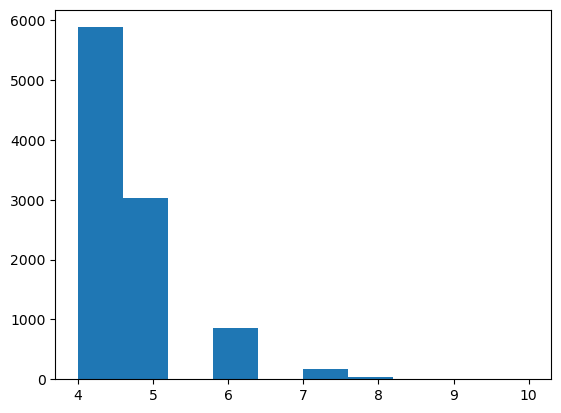

In [554]:
plt.hist(np.array(taos_perf))

In [547]:
.9*np.array(taos_perf).mean()/M, .9*np.array(taos_rand).mean()/M

(0.411147, 0.4723470000000001)

In [527]:
.5/.9

0.5555555555555556

In [528]:
.5/.8

0.625

(array([  4.,  19.,  86., 191., 247., 241., 133.,  58.,  18.,   3.]),
 array([0.74576 , 0.746641, 0.747522, 0.748403, 0.749284, 0.750165,
        0.751046, 0.751927, 0.752808, 0.753689, 0.75457 ]),
 <BarContainer object of 10 artists>)

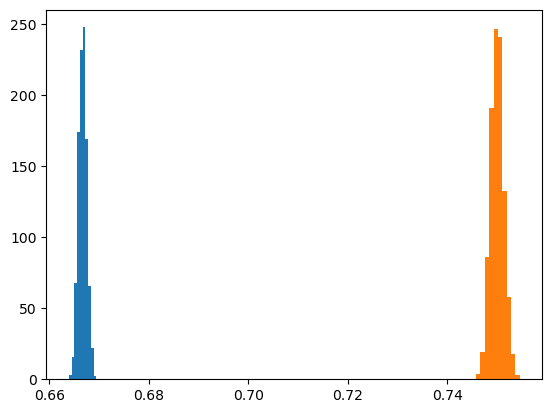

In [500]:
plt.hist(np.array(taos_perf)/N)
plt.hist(np.array(taos_rand)/N)


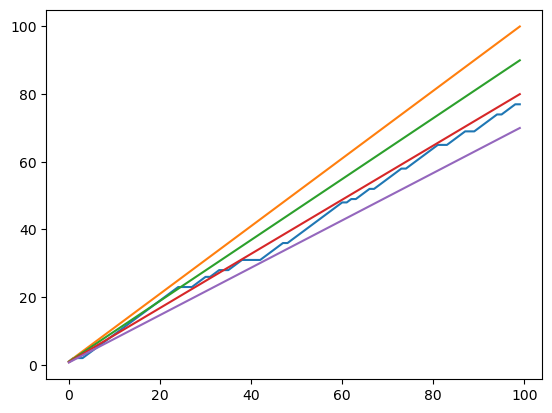

In [258]:
plt.plot(y.cumsum())
plt.plot(np.ones(100).cumsum())
plt.plot((np.ones(100)*.9).cumsum())
plt.plot((np.ones(100)*.8).cumsum())
plt.plot((np.ones(100)*.7).cumsum())

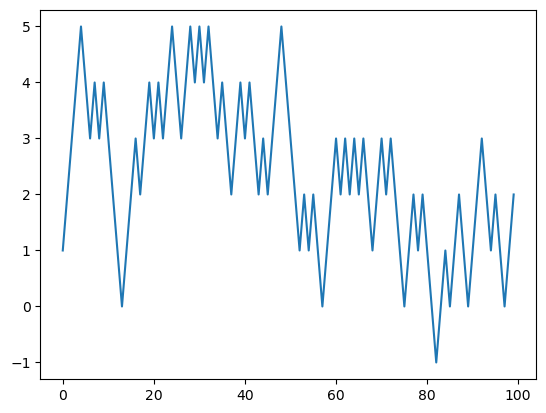

In [47]:
y = np.random.binomial(1, .58, 100)
y = 2 * y - 1
plt.plot(y.cumsum())

In [58]:
z.cumsum()

array([ 0,  0,  1,  1,  1,  1,  2,  2,  3,  4,  4,  5,  5,  6,  6,  6,  6,
        6,  7,  8,  8,  9,  9, 10, 10, 11, 12, 13, 13, 13, 13, 13, 13, 14,
       14, 14, 14, 15, 16, 17, 18, 19, 19, 20, 21, 21, 22, 22, 22, 22, 23,
       24, 25, 26, 26, 27, 28, 29, 29, 29, 29, 29, 29, 29, 30, 30, 30, 31,
       32, 32, 32, 32, 33, 33, 33, 34, 34, 34, 34, 34, 35, 36, 37, 37, 37,
       37, 37, 38, 38, 39, 39, 39, 40, 40, 40, 40, 41, 42, 43, 43])

In [61]:
z = np.random.binomial(1, .5, 100)
#z = 2 * z - 1


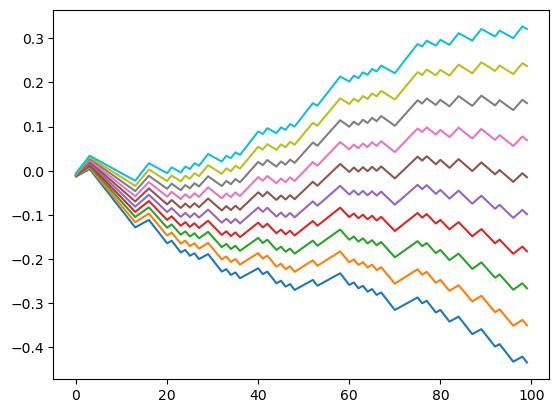

In [74]:

for a in np.linspace(0.3,.7, 10):
    plt.plot(np.arange(1, 101)/z.sum()*a-z.cumsum()/z.sum())

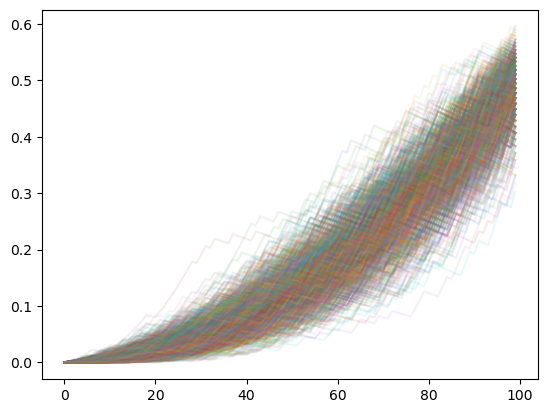

In [189]:

#for a in np.linspace(0.1,.9, 10):
#plt.plot(np.arange(1, 101)*.5-z.cumsum())
props = np.zeros(1000)
taos = np.zeros(1000)
mins = np.zeros(1000)
rho = .3
regrets = np.zeros((1000, 100))
for i in range(1000):
    z = np.random.binomial(1, p, 100)
    regrets[i,:] = np.power((np.arange(1, 101)/z.sum()*p*rho-z.cumsum()/z.sum()), 2)
    plt.plot(np.power(np.arange(1, 101)/z.sum()*p*rho-z.cumsum()/z.sum(), 2), alpha=.1)
    

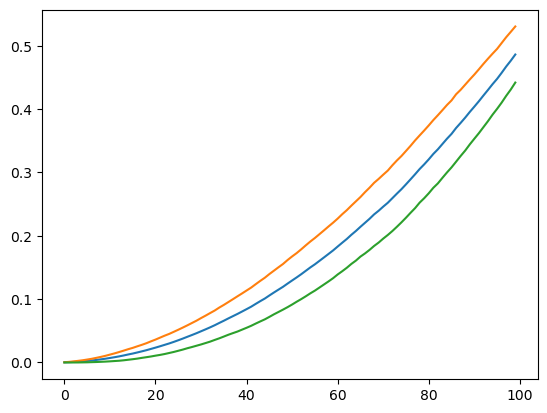

In [188]:
plt.plot(regrets.mean(0))
plt.plot(regrets.mean(0) + regrets.std(0))
plt.plot(regrets.mean(0) - regrets.std(0))

In [139]:

#for a in np.linspace(0.1,.9, 10):
#plt.plot(np.arange(1, 101)*.5-z.cumsum())
props = np.zeros(1000)
taos =np.zeros(1000)
mins =np.zeros(1000)
for i in range(1000):
    p = np.random.rand()
    #z = z[np.random.choice(100, 100, replace=False)]
    z = np.random.binomial(1, p, 100)
    tao = np.argmin(np.arange(1, 101)*p-z.cumsum())
    mins[i] = np.min(np.arange(1, 101)*p-z.cumsum())
    taos[i] = tao
    props[i] = z[:tao].sum() / (z.sum() + 1e-10)

In [140]:
np.random.rand()

0.746385717941634

In [141]:
taos.mean()

49.758

In [142]:
np.quantile(props,.1)

0.0

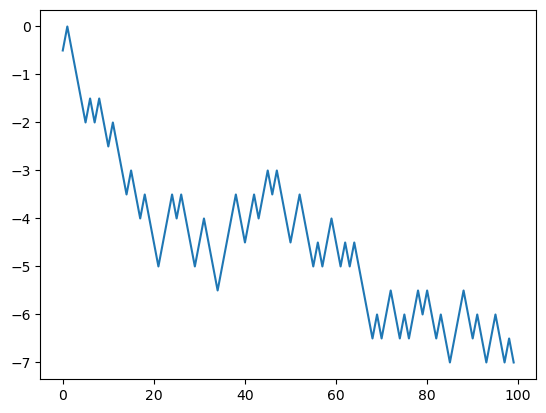

In [143]:
plt.plot(np.arange(1, 101)*.5-z.cumsum())

(array([214.,  89.,  60.,  68.,  60.,  59.,  66.,  80., 108., 196.]),
 array([ 0. ,  9.9, 19.8, 29.7, 39.6, 49.5, 59.4, 69.3, 79.2, 89.1, 99. ]),
 <BarContainer object of 10 artists>)

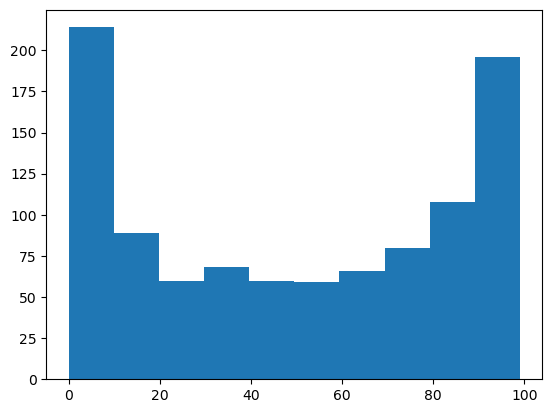

In [144]:
plt.hist(taos)

(array([197.,  84.,  53.,  57.,  61.,  51.,  70.,  78., 115., 234.]),
 array([0.   , 0.099, 0.198, 0.297, 0.396, 0.495, 0.594, 0.693, 0.792,
        0.891, 0.99 ]),
 <BarContainer object of 10 artists>)

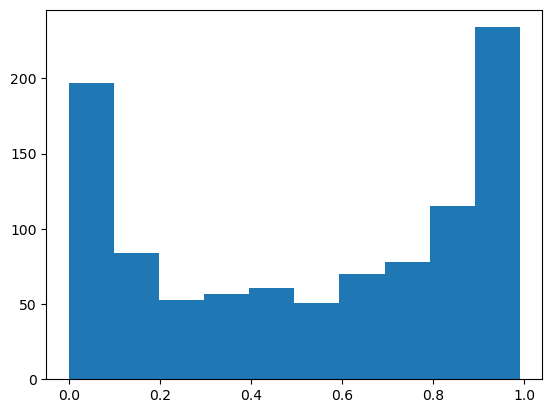

In [145]:
plt.hist(props)

(array([  2.,   1.,  11.,  20.,  45.,  69., 129., 182., 264., 277.]),
 array([-14.53769248, -13.02716834, -11.51664421, -10.00612007,
         -8.49559593,  -6.9850718 ,  -5.47454766,  -3.96402352,
         -2.45349938,  -0.94297525,   0.56754889]),
 <BarContainer object of 10 artists>)

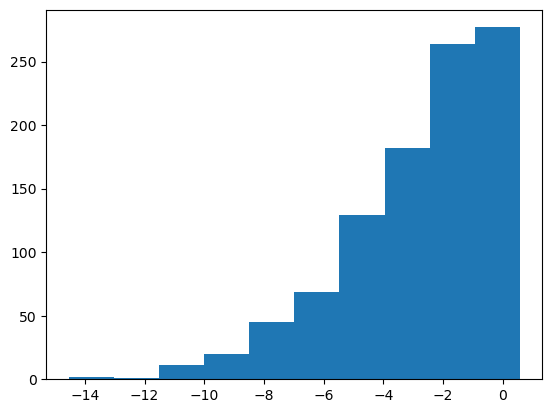

In [146]:
plt.hist(mins)